# Mini-eksperimen Anggota A — Minggu 6 (String Search) dan Minggu 9–10 (Fuzzy)

**Tugas (Rencana Kerja, mini-eksperimen mingguan Anggota A):** *"dokumentasikan sebagai latihan; tidak wajib masuk metode final"*.

| Minggu | Materi | Tugas di Rencana Kerja |
| --- | --- | --- |
| 6 | String search | Diskretisasi kontur F0 per frame menjadi token naik/turun/datar, lalu cari pola dengan KMP. Catat kenapa *exact matching* gagal pada variasi ujaran. |
| 9–10 | Fuzzy logic | Buat fuzzy rule sederhana "arousal" dari F0 mean dan RMS (rendah/sedang/tinggi), uji pada ≥ 3 contoh audio, lalu putuskan dipakai atau tidak. |

**Aturan data:** hanya data train (aktor 1–16) dan validation (aktor 17–20) yang dipakai. Data test (aktor 21–24) tidak disentuh.

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/processed/ravdess_16k_trim/`, `data/metadata.csv` | Audio aktor 1 dan 2 untuk bagian KMP |
| Input | `data/features/features_none.csv`, `data/splits.json`, `config.json` | Fitur F0 dan RMS untuk bagian fuzzy |
| Output | `results/mini_eksperimen_A.json` | Angka hasil kedua mini-eksperimen |
| Output | `figures/mini/` | 4 grafik + `mini_summary.txt` |
| Output | `docs/README_mini_eksperimen_A.md` | Dokumentasi standar |

**Perkiraan waktu:** 1–3 menit. **Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

In [1]:
import os
import re
import sys
import json
import time
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
PROC_DIR = os.path.join(DATA_DIR, 'processed', 'ravdess_16k_trim')
SRC_DIR = os.path.join(BASE_DIR, 'src')
RES_DIR = os.path.join(BASE_DIR, 'results')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'mini')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
for d in [RES_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = [CONFIG_PATH, PROC_DIR, os.path.join(DATA_DIR, 'metadata.csv'), os.path.join(DATA_DIR, 'splits.json'),
         os.path.join(DATA_DIR, 'features', 'features_none.csv'), os.path.join(SRC_DIR, 'data_splits.py')]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('Prasyarat tidak ditemukan:\n' + '\n'.join(hilang))
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import data_splits as ds

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
FC = CONFIG['features']
S = ds.load_splits(BASE_DIR)
meta = pd.read_csv(os.path.join(DATA_DIR, 'metadata.csv'))

BIRU, ORANYE, HIJAU, ABU = '#2a78d6', '#eb6834', '#3c9c6c', '#8a8985'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})
HASIL = {'created': datetime.now().strftime('%Y-%m-%d %H:%M'), 'owner': 'Anggota A'}
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/project07


---
# Bagian A — Minggu 6: Pencarian pola kontur F0 dengan KMP

**Ide:** intonasi bisa ditulis sebagai rangkaian huruf. Kontur F0 dipotong per 50 ms (5 frame), lalu setiap potongan diberi token:

| Token | Arti | Aturan |
| --- | --- | --- |
| `N` | Naik | rata-rata F0 potongan ini > potongan sebelumnya + 0,5 semitone |
| `T` | Turun | < potongan sebelumnya − 0,5 semitone |
| `D` | Datar | perubahan di antara ±0,5 semitone |
| `U` | Tidak bersuara | > 50% frame potongan tanpa nada; beberapa `U` berurutan digabung jadi satu |

F0 diubah ke **semitone** (skala logaritmik) supaya naik 0,5 semitone berarti sama untuk suara laki-laki dan perempuan. Lalu **KMP (Knuth–Morris–Pratt)** mencari apakah pola intonasi dari satu rekaman muncul persis di rekaman lain.

**Data:** aktor 1 (laki-laki) dan 2 (perempuan), kalimat 1, semua emosi dan pengulangan (60 file, semuanya data train).

## Sel A1 — Tokenisasi kontur F0 dan implementasi KMP

In [2]:
SEG = 5          # frame per potongan (5 x 10 ms = 50 ms)
THR = 0.5        # ambang naik/turun dalam semitone

def kontur_f0(path):
    y, sr = sf.read(path, dtype='float32')
    yu = y / max(float(np.max(np.abs(y))), 1e-9)
    f0, vf, _ = librosa.pyin(yu, fmin=FC['f0_fmin'], fmax=FC['f0_fmax'], sr=sr,
                             frame_length=FC['f0_frame_length'], hop_length=FC['hop_length'])
    return 12 * np.log2(np.where(vf, f0, np.nan) / 100.0)     # semitone relatif 100 Hz

def tokenisasi(st):
    out, prev = [], None
    for i in range(len(st) // SEG):
        b = st[i * SEG:(i + 1) * SEG]
        if np.isnan(b).mean() > 0.5:
            out.append('U')
            prev = None
            continue
        m = np.nanmean(b)
        if prev is not None:
            d = m - prev
            out.append('N' if d > THR else 'T' if d < -THR else 'D')
        prev = m
    return re.sub('U+', 'U', ''.join(out)).strip('U')

def prefix_function(pat):
    pi, k = [0] * len(pat), 0
    for i in range(1, len(pat)):
        while k and pat[i] != pat[k]:
            k = pi[k - 1]
        if pat[i] == pat[k]:
            k += 1
        pi[i] = k
    return pi

def kmp_search(text, pat):
    # Semua posisi kemunculan pat di text, O(len(text) + len(pat))
    if not pat:
        return []
    pi, k, hasil = prefix_function(pat), 0, []
    for i, c in enumerate(text):
        while k and c != pat[k]:
            k = pi[k - 1]
        if c == pat[k]:
            k += 1
        if k == len(pat):
            hasil.append(i - k + 1)
            k = pi[k - 1]
    return hasil

def naive_search(text, pat):
    return [i for i in range(len(text) - len(pat) + 1) if text[i:i + len(pat)] == pat]

rng = np.random.default_rng(0)
uji_ok = all(kmp_search(t, p) == naive_search(t, p)
             for t, p in ((''.join(rng.choice(list('NTD'), rng.integers(1, 60))),
                           ''.join(rng.choice(list('NTD'), rng.integers(1, 6)))) for _ in range(2000)))
print('KMP = pencarian naif pada 2.000 pasangan acak:', uji_ok)
print('Contoh prefix function "NNDNN":', prefix_function('NNDNN'))

KMP = pencarian naif pada 2.000 pasangan acak: True
Contoh prefix function "NNDNN": [0, 1, 0, 1, 2]


## Sel A2 — Token untuk 60 rekaman (±20–60 detik)

In [3]:
sel = meta[(meta['actor'].isin([1, 2])) & (meta['statement'] == 1)].copy().reset_index(drop=True)
assert set(sel['actor']) <= set(S['train'])
t0 = time.time()
KONTUR, TOKEN = {}, {}
for f in sel['file']:
    KONTUR[f] = kontur_f0(os.path.join(PROC_DIR, f))
    TOKEN[f] = tokenisasi(KONTUR[f])
sel['token'] = sel['file'].map(TOKEN)
sel['panjang'] = sel['token'].str.len()
print(f'{len(sel)} rekaman ditokenisasi dalam {time.time() - t0:.0f} detik; panjang token median {int(sel["panjang"].median())}')
display(sel[['file', 'emotion', 'intensity', 'repetition', 'token']].head(6))

60 rekaman ditokenisasi dalam 83 detik; panjang token median 26


,file,emotion,intensity,repetition,token
0,Actor_01/03-01-01-01-01-01-01.wav,neutral,normal,1,TTTTDUTUTTDDTDDNDTTDDN
1,Actor_01/03-01-01-01-01-02-01.wav,neutral,normal,2,TTTDTDNNTUTTDDDDTDDTTTDD
2,Actor_01/03-01-02-01-01-01-01.wav,calm,normal,1,DTTUTDUTDDTTTDDDTTNTTTDD
3,Actor_01/03-01-02-01-01-02-01.wav,calm,normal,2,DTTTDTTTDNUTTUTTTDDDDDTNTTTDDD
4,Actor_01/03-01-02-02-01-01-01.wav,calm,strong,1,TDTTDTTDUTTTNTTTTDNDDDDTNDDTTDNN
5,Actor_01/03-01-02-02-01-02-01.wav,calm,strong,2,DTTTTUTDUTTUTTDTTDDDDNTDDTTDDDD


## Sel A3 — Eksperimen: apakah pola intonasi muncul lagi?

Untuk setiap pasangan rekaman dengan aktor, emosi, dan intensitas sama, pengulangan ke-1 dipotong menjadi pola sepanjang L token (tanpa `U`). Lalu dihitung:

- **sama emosi:** proporsi pola yang ditemukan persis (KMP) di pengulangan ke-2, yaitu kalimat yang sama, diucapkan orang yang sama, dengan emosi yang sama;
- **beda emosi:** rata-rata proporsi pola yang ditemukan di rekaman emosi lain dari aktor yang sama.

Sebagai pembanding, dihitung juga **pencocokan mendekati** (*approximate matching*): jarak edit terkecil antara pola dan potongan mana pun di teks (algoritma Sellers), dibagi panjang pola. Nilai 0 berarti cocok persis.

In [4]:
def jarak_terdekat(text, pat):
    # Jarak edit terkecil antara pat dan substring mana pun dari text (Sellers 1980)
    prev = list(range(len(pat) + 1))
    terbaik = prev[-1]
    for c in text:
        cur = [0]
        for j in range(1, len(pat) + 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (pat[j - 1] != c)))
        terbaik = min(terbaik, cur[-1])
        prev = cur
    return terbaik

sel['kunci'] = list(zip(sel['actor'], sel['emotion'], sel['intensity']))
PANJANG = [4, 6, 8, 10, 12]
baris = []
for L in PANJANG:
    sama, beda, d_sama, d_beda = [], [], [], []
    for kunci, grp in sel.groupby('kunci'):
        if len(grp) < 2:
            continue
        a, b = grp['token'].iloc[0], grp['token'].iloc[1]
        pola = [a[i:i + L] for i in range(0, len(a) - L + 1, L) if 'U' not in a[i:i + L]]
        if not pola:
            continue
        lain = sel[(sel['actor'] == kunci[0]) & (sel['emotion'] != kunci[1])]['token'].tolist()
        sama.append(np.mean([bool(kmp_search(b, p)) for p in pola]))
        beda.append(np.mean([np.mean([bool(kmp_search(o, p)) for o in lain]) for p in pola]))
        d_sama.append(np.mean([jarak_terdekat(b, p) / L for p in pola]))
        d_beda.append(np.mean([np.mean([jarak_terdekat(o, p) / L for o in lain]) for p in pola]))
    baris.append({'L': L, 'ditemukan persis, sama emosi': round(np.mean(sama), 3),
                  'ditemukan persis, beda emosi': round(np.mean(beda), 3),
                  'jarak edit relatif, sama emosi': round(np.mean(d_sama), 3),
                  'jarak edit relatif, beda emosi': round(np.mean(d_beda), 3), 'jumlah pasangan': len(sama)})
KMP_TAB = pd.DataFrame(baris)
display(KMP_TAB)
HASIL['kmp'] = {'seg_ms': SEG * 10, 'threshold_semitone': THR, 'n_files': len(sel), 'actors': [1, 2],
                'kmp_equals_naive': bool(uji_ok), 'table': KMP_TAB.to_dict(orient='records')}

,L,"ditemukan persis, sama emosi","ditemukan persis, beda emosi","jarak edit relatif, sama emosi","jarak edit relatif, beda emosi",jumlah pasangan
0,4,0.400,0.278,0.168,0.205,29
1,6,0.098,0.051,0.250,0.275,29
2,8,0.019,0.005,0.247,0.311,27
3,10,0.000,0.000,0.250,0.328,21
4,12,0.000,0.000,0.257,0.358,17


## Sel A4 — Grafik bagian A

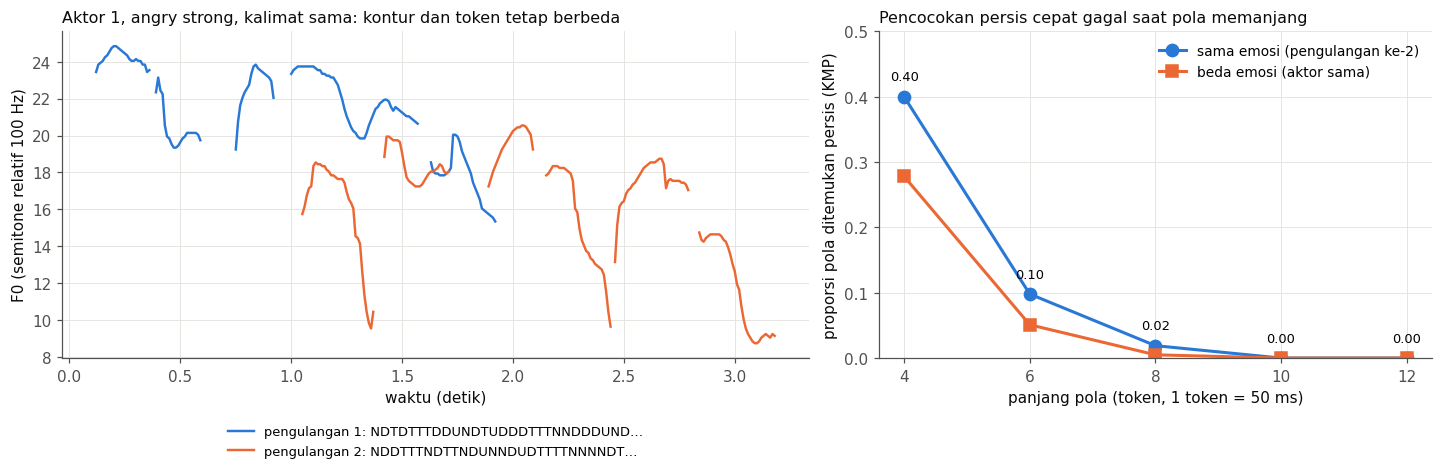

In [5]:
grp = sel[(sel['actor'] == 1) & (sel['emotion'] == 'angry') & (sel['intensity'] == 'strong')].sort_values('repetition')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), layout='constrained', gridspec_kw={'width_ratios': [1.35, 1]})
ax = axes[0]
for (f, rep), c in zip(zip(grp['file'], grp['repetition']), [BIRU, ORANYE]):
    st = KONTUR[f]
    t = np.arange(len(st)) * FC['hop_length'] / FC['sr']
    ax.plot(t, st, color=c, lw=1.6, label=f'pengulangan {rep}: {TOKEN[f][:28]}{"…" if len(TOKEN[f]) > 28 else ""}')
ax.set_xlabel('waktu (detik)')
ax.set_ylabel('F0 (semitone relatif 100 Hz)')
ax.grid(color='#e4e3df', lw=0.6)
ax.legend(frameon=False, fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=1)
ax.set_title('Aktor 1, angry strong, kalimat sama: kontur dan token tetap berbeda', loc='left', fontsize=10.5)
ax = axes[1]
ax.plot(KMP_TAB['L'], KMP_TAB['ditemukan persis, sama emosi'], 'o-', color=BIRU, lw=2, ms=8, label='sama emosi (pengulangan ke-2)')
ax.plot(KMP_TAB['L'], KMP_TAB['ditemukan persis, beda emosi'], 's-', color=ORANYE, lw=2, ms=8, label='beda emosi (aktor sama)')
for _, r in KMP_TAB.iterrows():
    ax.text(r['L'], r['ditemukan persis, sama emosi'] + 0.025, f"{r['ditemukan persis, sama emosi']:.2f}", ha='center', fontsize=8.5)
ax.set_xticks(PANJANG)
ax.set_xlabel('panjang pola (token, 1 token = 50 ms)')
ax.set_ylabel('proporsi pola ditemukan persis (KMP)')
ax.set_ylim(0, max(0.5, KMP_TAB['ditemukan persis, sama emosi'].max() + 0.1))
ax.grid(color='#e4e3df', lw=0.6)
ax.legend(frameon=False, fontsize=9)
ax.set_title('Pencocokan persis cepat gagal saat pola memanjang', loc='left', fontsize=10.5)
fig.savefig(os.path.join(FIG_DIR, 'mini_01_kmp_kontur_f0.png'))
plt.show()

## Kesimpulan bagian A: kenapa *exact matching* gagal

Sel berikut menulis kesimpulan dari angka di atas.

In [6]:
r4 = KMP_TAB.iloc[0]
rL = KMP_TAB.iloc[-1]
r8 = KMP_TAB[KMP_TAB['L'] == 8].iloc[0]
KESIMPULAN_A = [
    f"Bahkan untuk kalimat, aktor, dan emosi yang sama, pola {int(r4['L'])} token (200 ms) hanya ditemukan persis pada "
    f"{r4['ditemukan persis, sama emosi']:.0%} kasus, dan pola {int(rL['L'])} token pada {rL['ditemukan persis, sama emosi']:.0%} kasus.",
    'Penyebabnya: ucapan manusia tidak pernah persis sama. Sedikit perbedaan tempo menggeser batas potongan 50 ms, '
    'perubahan nada di dekat ambang 0,5 semitone berpindah antara N/T dan D, dan frame tak bersuara menyisipkan U di posisi berbeda. '
    'Satu token yang berbeda saja sudah membuat KMP gagal.',
    f"Pola pendek yang masih sering ditemukan juga tidak membedakan emosi: {r4['ditemukan persis, sama emosi']:.0%} (sama emosi) "
    f"vs {r4['ditemukan persis, beda emosi']:.0%} (beda emosi), karena pola pendek naik-turun-datar lazim muncul di banyak ujaran, apa pun emosinya.",
    f"Pencocokan mendekati lebih masuk akal: pada L = 8, jarak edit relatif ke pengulangan emosi yang sama "
    f"{r8['jarak edit relatif, sama emosi']:.2f} vs {r8['jarak edit relatif, beda emosi']:.2f} ke emosi lain. Selisihnya kecil, "
    'jadi bentuk kontur saja lemah untuk mengenali emosi.',
    'Keputusan: tidak dipakai di metode final. Statistik ringkas F0 (rata-rata, simpangan baku, persentil, rentang) di 90 fitur '
    'lebih tahan terhadap variasi ujaran dibanding urutan token persis.']
for i, k in enumerate(KESIMPULAN_A, 1):
    print(f'{i}. {k}')
HASIL['kmp']['kesimpulan'] = KESIMPULAN_A

1. Bahkan untuk kalimat, aktor, dan emosi yang sama, pola 4 token (200 ms) hanya ditemukan persis pada 40% kasus, dan pola 12 token pada 0% kasus.
2. Penyebabnya: ucapan manusia tidak pernah persis sama. Sedikit perbedaan tempo menggeser batas potongan 50 ms, perubahan nada di dekat ambang 0,5 semitone berpindah antara N/T dan D, dan frame tak bersuara menyisipkan U di posisi berbeda. Satu token yang berbeda saja sudah membuat KMP gagal.
3. Pola pendek yang masih sering ditemukan juga tidak membedakan emosi: 40% (sama emosi) vs 28% (beda emosi), karena pola pendek naik-turun-datar lazim muncul di banyak ujaran, apa pun emosinya.
4. Pencocokan mendekati lebih masuk akal: pada L = 8, jarak edit relatif ke pengulangan emosi yang sama 0.25 vs 0.31 ke emosi lain. Selisihnya kecil, jadi bentuk kontur saja lemah untuk mengenali emosi.
5. Keputusan: tidak dipakai di metode final. Statistik ringkas F0 (rata-rata, simpangan baku, persentil, rentang) di 90 fitur lebih tahan terhadap variasi ujara

---
# Bagian B — Minggu 9–10: Fuzzy rule "arousal" dari F0 dan RMS

**Arousal** adalah tingkat keterbangkitan emosi: tenang ↔ bersemangat. Pembagian emosi RAVDESS ke tiga tingkat arousal mengikuti model sirkumpleks emosi yang umum dipakai, dan menjadi bagian dari *knowledge map* proyek:

| Arousal | Emosi |
| --- | --- |
| Rendah | neutral, calm, sad |
| Sedang | disgust |
| Tinggi | happy, angry, fearful, surprised |

**Masukan:**
- **F0 mean**: nada rata-rata. Karena nada perempuan sekitar 100 Hz lebih tinggi daripada laki-laki (temuan langkah 5), batas rendah/sedang/tinggi dibuat **terpisah per gender**.
- **RMS (dB)**: kerasnya suara, dari `features_none.csv`. Versi `none` dipakai karena normalisasi puncak menghapus perbedaan keras-pelan, padahal keras-pelan adalah petunjuk utama arousal.

**Fungsi keanggotaan:** segitiga dan bahu dengan titik P10, P50, P90 data train. Nilai di P50 sepenuhnya "sedang", di bawah P10 sepenuhnya "rendah", di atas P90 sepenuhnya "tinggi".

**Aturan:** 9 aturan (3 × 3), operator AND = minimum, keluaran tunggal (*singleton*) rendah = 0, sedang = 0,5, tinggi = 1, lalu dirata-rata berbobot (fuzzy Sugeno orde nol). Skor ≤ 1/3 → rendah, ≥ 2/3 → tinggi, di antaranya → sedang.

## Sel B1 — Fungsi keanggotaan dan aturan

In [7]:
fn = pd.read_csv(os.path.join(DATA_DIR, 'features', 'features_none.csv'))
tr, va, _ = ds.split_frames(fn, S)               # test sengaja dibuang
AROUSAL = {'neutral': 'rendah', 'calm': 'rendah', 'sad': 'rendah', 'disgust': 'sedang',
           'happy': 'tinggi', 'angry': 'tinggi', 'fearful': 'tinggi', 'surprised': 'tinggi'}
for d in (tr, va):
    d['rms_db'] = 20 * np.log10(d['rms_mean'] + 1e-9)
    d['arousal'] = d['emotion'].map(AROUSAL)

ber_nada = tr[tr['voiced_ratio'] > 0]
TITIK = {('f0', g): np.percentile(x['f0_mean'], [10, 50, 90]) for g, x in ber_nada.groupby('gender')}
TITIK[('f0', 'semua')] = np.percentile(ber_nada['f0_mean'], [10, 50, 90])
TITIK[('rms', 'semua')] = np.percentile(tr['rms_db'], [10, 50, 90])
print('Titik P10 / P50 / P90 dari data train:')
for (v, g), p in TITIK.items():
    satuan = 'Hz' if v == 'f0' else 'dB'
    print(f'  {v:<3} {g:<7}: ' + ' / '.join(f'{x:.1f}' for x in p) + f' {satuan}')

def keanggotaan(x, p):
    lo, mid, hi = p
    return {'rendah': float(np.clip((mid - x) / (mid - lo), 0, 1)),
            'sedang': float(np.clip(1 - (abs(x - mid) / ((mid - lo) if x < mid else (hi - mid))), 0, 1)),
            'tinggi': float(np.clip((x - mid) / (hi - mid), 0, 1))}

ATURAN = {('rendah', 'rendah'): 'rendah', ('rendah', 'sedang'): 'rendah', ('rendah', 'tinggi'): 'sedang',
          ('sedang', 'rendah'): 'rendah', ('sedang', 'sedang'): 'sedang', ('sedang', 'tinggi'): 'tinggi',
          ('tinggi', 'rendah'): 'sedang', ('tinggi', 'sedang'): 'tinggi', ('tinggi', 'tinggi'): 'tinggi'}
KELUARAN = {'rendah': 0.0, 'sedang': 0.5, 'tinggi': 1.0}

def fuzzy_arousal(f0, rms_db, gender, voiced_ratio, per_gender=True, detail=False):
    if voiced_ratio > 0:
        m_f0 = keanggotaan(f0, TITIK[('f0', gender if per_gender else 'semua')])
    else:                                     # nada tidak terdeteksi: F0 dianggap netral
        m_f0 = {'rendah': 0.0, 'sedang': 1.0, 'tinggi': 0.0}
    m_rms = keanggotaan(rms_db, TITIK[('rms', 'semua')])
    num = den = 0.0
    aktif = []
    for (a, b), o in ATURAN.items():
        w = min(m_f0[a], m_rms[b])
        if w > 0:
            aktif.append((f'F0 {a} DAN RMS {b} -> {o}', round(w, 2)))
        num += w * KELUARAN[o]
        den += w
    skor = num / den if den > 0 else 0.5
    kelas = 'rendah' if skor <= 1 / 3 else 'tinggi' if skor >= 2 / 3 else 'sedang'
    return (skor, kelas, m_f0, m_rms, aktif) if detail else (skor, kelas)

print('\nTabel aturan (baris = F0, kolom = RMS):')
display(pd.DataFrame([[ATURAN[(a, b)] for b in ['rendah', 'sedang', 'tinggi']] for a in ['rendah', 'sedang', 'tinggi']],
                     index=['F0 rendah', 'F0 sedang', 'F0 tinggi'], columns=['RMS rendah', 'RMS sedang', 'RMS tinggi']))

Titik P10 / P50 / P90 dari data train:
  f0  female : 202.6 / 258.7 / 375.3 Hz
  f0  male   : 102.7 / 149.0 / 270.6 Hz
  f0  semua  : 113.7 / 219.3 / 339.0 Hz
  rms semua  : -51.1 / -40.0 / -26.6 dB

Tabel aturan (baris = F0, kolom = RMS):


,RMS rendah,RMS sedang,RMS tinggi
F0 rendah,rendah,rendah,sedang
F0 sedang,rendah,sedang,tinggi
F0 tinggi,sedang,tinggi,tinggi


## Sel B2 — Uji pada contoh audio (Rencana Kerja: ≥ 3 contoh)

Empat rekaman aktor 1 (train), kalimat 1, pengulangan 1: dua arousal rendah dan dua arousal tinggi.

In [8]:
contoh_kunci = [('calm', 'normal'), ('sad', 'normal'), ('happy', 'strong'), ('angry', 'strong')]
CONTOH = []
for emo, inten in contoh_kunci:
    r = tr[(tr['actor'] == 1) & (tr['emotion'] == emo) & (tr['intensity'] == inten)
           & tr['file'].str.contains(r'-01-01-01\.wav$')].iloc[0]
    skor, kelas, m_f0, m_rms, aktif = fuzzy_arousal(r['f0_mean'], r['rms_db'], r['gender'], r['voiced_ratio'], detail=True)
    CONTOH.append({'file': r['file'], 'emosi': f'{emo} {inten}', 'arousal seharusnya': AROUSAL[emo],
                   'F0 mean (Hz)': round(r['f0_mean'], 1), 'RMS (dB)': round(r['rms_db'], 1),
                   'F0 (r/s/t)': '/'.join(f'{m_f0[k]:.2f}' for k in ['rendah', 'sedang', 'tinggi']),
                   'RMS (r/s/t)': '/'.join(f'{m_rms[k]:.2f}' for k in ['rendah', 'sedang', 'tinggi']),
                   'aturan aktif': '; '.join(f'{a} ({w})' for a, w in aktif),
                   'skor': round(skor, 2), 'hasil fuzzy': kelas, 'benar': kelas == AROUSAL[emo]})
CONTOH_DF = pd.DataFrame(CONTOH)
pd.set_option('display.max_colwidth', 90)
display(CONTOH_DF)
print(f"Benar {int(CONTOH_DF['benar'].sum())} dari {len(CONTOH_DF)} contoh")

,file,emosi,arousal seharusnya,F0 mean (Hz),RMS (dB),F0 (r/s/t),RMS (r/s/t),aturan aktif,skor,hasil fuzzy,benar
0,Actor_01/03-01-02-01-01-01-01.wav,calm normal,rendah,117.7,-49.5,0.67/0.33/0.00,0.86/0.14/0.00,F0 rendah DAN RMS rendah -> rendah (0.67); F0 rendah DAN RMS sedang -> rendah (0.14); ...,0.05,rendah,True
1,Actor_01/03-01-04-01-01-01-01.wav,sad normal,rendah,125.5,-47.8,0.51/0.49/0.00,0.70/0.30/0.00,F0 rendah DAN RMS rendah -> rendah (0.51); F0 rendah DAN RMS sedang -> rendah (0.3); F...,0.09,rendah,True
2,Actor_01/03-01-03-02-01-01-01.wav,happy strong,tinggi,215.1,-37.7,0.00/0.46/0.54,0.00/0.83/0.17,F0 sedang DAN RMS sedang -> sedang (0.46); F0 sedang DAN RMS tinggi -> tinggi (0.17); ...,0.83,tinggi,True
3,Actor_01/03-01-05-02-01-01-01.wav,angry strong,tinggi,346.4,-20.3,0.00/0.00/1.00,0.00/0.00/1.00,F0 tinggi DAN RMS tinggi -> tinggi (1.0),1.00,tinggi,True


Benar 4 dari 4 contoh


## Sel B3 — Evaluasi di train dan validation

Selain contoh, aturan diuji pada seluruh train (aktor 1–16) dan validation (aktor 17–20):
- **Akurasi biner:** tinggi vs rendah (disgust dikeluarkan), dengan skor ≥ 0,5 berarti tinggi.
- **Akurasi 3 kelas:** rendah/sedang/tinggi.
- **Varian tanpa gender:** batas F0 digabung untuk semua orang, untuk melihat kerugiannya jika gender tidak diketahui (misalnya di demo).

In [9]:
def evaluasi(d, per_gender=True):
    skor = np.array([fuzzy_arousal(r.f0_mean, r.rms_db, r.gender, r.voiced_ratio, per_gender)[0] for r in d.itertuples()])
    kelas = np.where(skor <= 1 / 3, 'rendah', np.where(skor >= 2 / 3, 'tinggi', 'sedang'))
    m = d['arousal'].isin(['rendah', 'tinggi']).to_numpy()
    biner = np.where(skor >= 0.5, 'tinggi', 'rendah')
    return {'akurasi_biner': round(float((biner[m] == d['arousal'].to_numpy()[m]).mean()), 3),
            'akurasi_3kelas': round(float((kelas == d['arousal'].to_numpy()).mean()), 3),
            'skor_per_emosi': pd.Series(skor, index=d.index).groupby(d['emotion']).mean().round(3).to_dict()}, skor, kelas

EVAL_FZ = {}
for nama, d in [('train', tr), ('validation', va)]:
    for pg in (True, False):
        hasil, skor, kelas = evaluasi(d, pg)
        EVAL_FZ[(nama, pg)] = hasil
        if nama == 'validation' and pg:
            SKOR_VA, KELAS_VA = skor, kelas
TAB_FZ = pd.DataFrame([{'data': n, 'batas F0': 'per gender' if pg else 'digabung',
                        'akurasi biner (tinggi vs rendah)': v['akurasi_biner'], 'akurasi 3 kelas': v['akurasi_3kelas']}
                       for (n, pg), v in EVAL_FZ.items()])
display(TAB_FZ)
print('Tabel silang validation (per gender), baris = arousal seharusnya, kolom = hasil fuzzy:')
display(pd.crosstab(va['arousal'], KELAS_VA).reindex(index=['rendah', 'sedang', 'tinggi'], columns=['rendah', 'sedang', 'tinggi'], fill_value=0))
SKOR_EMO = pd.Series(EVAL_FZ[('validation', True)]['skor_per_emosi']).sort_values()
print('Skor arousal rata-rata per emosi (validation):', SKOR_EMO.round(2).to_dict())

,data,batas F0,akurasi biner (tinggi vs rendah),akurasi 3 kelas
0,train,per gender,0.784,0.627
1,train,digabung,0.757,0.592
2,validation,per gender,0.774,0.629
3,validation,digabung,0.755,0.621


Tabel silang validation (per gender), baris = arousal seharusnya, kolom = hasil fuzzy:


col_0,rendah,sedang,tinggi
arousal,,,
rendah,61,7,12
sedang,8,10,14
tinggi,21,27,80


Skor arousal rata-rata per emosi (validation): {'calm': 0.05, 'neutral': 0.07, 'sad': 0.47, 'disgust': 0.58, 'surprised': 0.63, 'happy': 0.7, 'angry': 0.73, 'fearful': 0.77}


## Sel B4 — Grafik bagian B

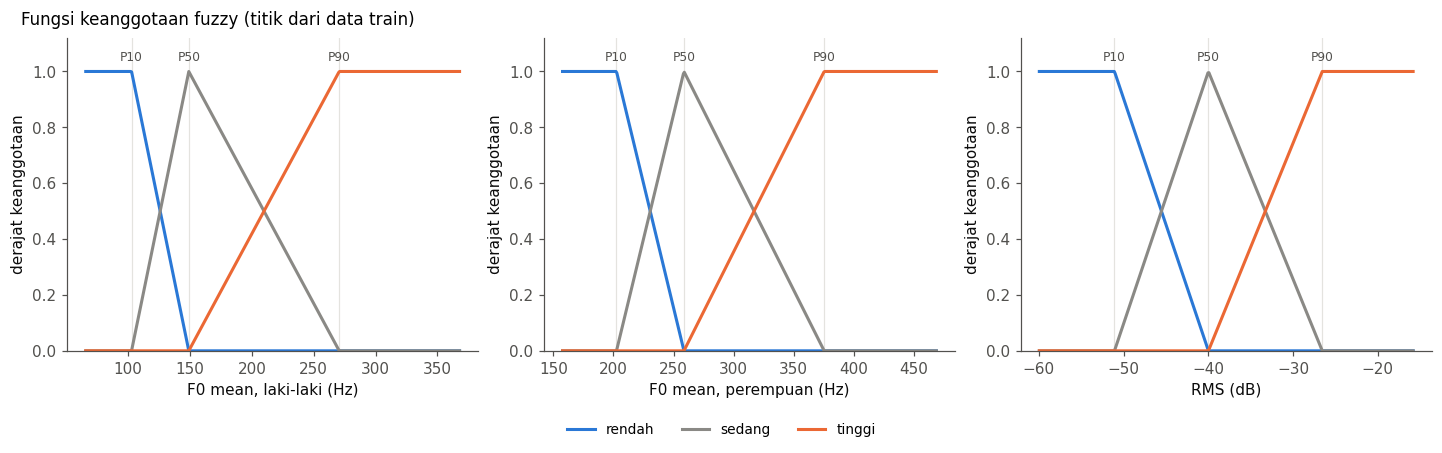

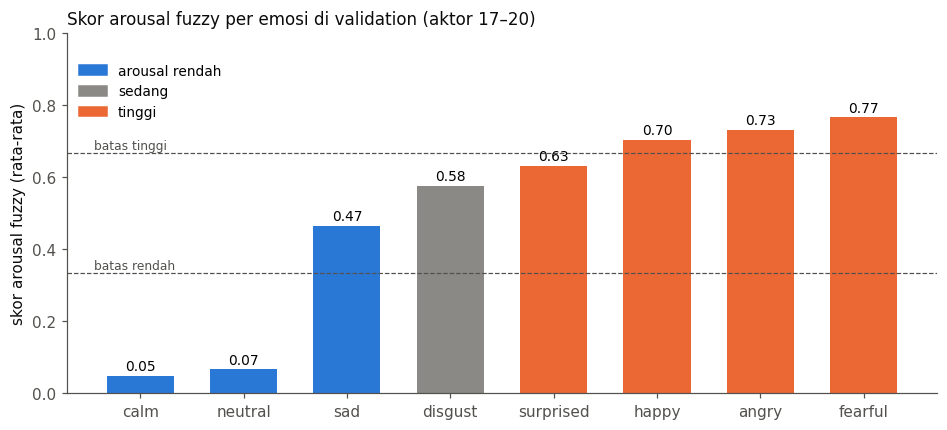

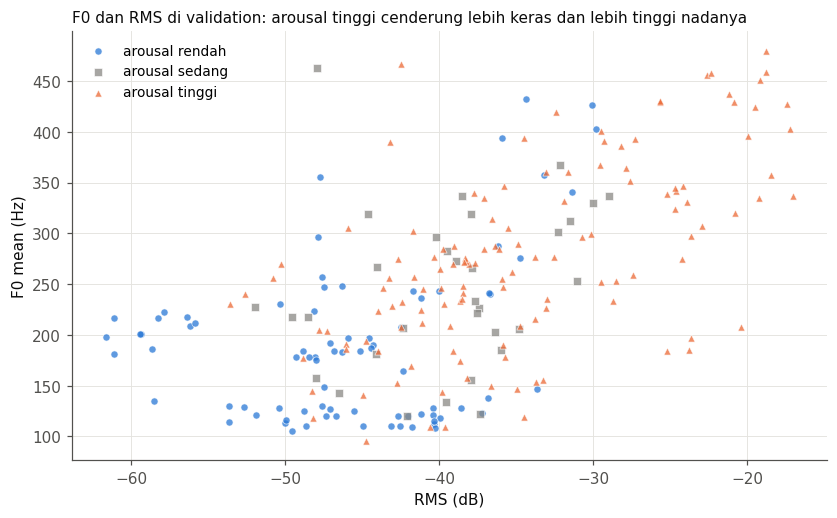

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout='constrained')
panel = [(('f0', 'male'), 'F0 mean, laki-laki (Hz)'), (('f0', 'female'), 'F0 mean, perempuan (Hz)'), (('rms', 'semua'), 'RMS (dB)')]
for ax, (kunci, judul) in zip(axes, panel):
    lo, mid, hi = TITIK[kunci]
    xs = np.linspace(lo - (mid - lo) * 0.8, hi + (hi - mid) * 0.8, 400)
    M = [keanggotaan(x, TITIK[kunci]) for x in xs]
    for nama, c in [('rendah', BIRU), ('sedang', ABU), ('tinggi', ORANYE)]:
        ax.plot(xs, [m[nama] for m in M], color=c, lw=2, label=nama)
    for x, t in zip((lo, mid, hi), ('P10', 'P50', 'P90')):
        ax.axvline(x, color='#e4e3df', lw=0.8, zorder=0)
        ax.text(x, 1.04, t, ha='center', fontsize=8, color='#52514e')
    ax.set_ylim(0, 1.12)
    ax.set_xlabel(judul)
    ax.set_ylabel('derajat keanggotaan')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
fig.suptitle('Fungsi keanggotaan fuzzy (titik dari data train)', x=0.01, ha='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mini_02_fuzzy_keanggotaan.png'))
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.8), layout='constrained')
warna = [BIRU if AROUSAL[e] == 'rendah' else ABU if AROUSAL[e] == 'sedang' else ORANYE for e in SKOR_EMO.index]
bars = ax.bar(range(len(SKOR_EMO)), SKOR_EMO.values, color=warna, width=0.65)
for r, v in zip(bars, SKOR_EMO.values):
    ax.text(r.get_x() + r.get_width() / 2, v + 0.015, f'{v:.2f}', ha='center', fontsize=9)
ax.axhline(1 / 3, color='#52514e', lw=0.8, ls='--')
ax.axhline(2 / 3, color='#52514e', lw=0.8, ls='--')
ax.text(-0.45, 1 / 3 + 0.012, 'batas rendah', ha='left', fontsize=8, color='#52514e')
ax.text(-0.45, 2 / 3 + 0.012, 'batas tinggi', ha='left', fontsize=8, color='#52514e')
ax.set_xticks(range(len(SKOR_EMO)))
ax.set_xticklabels(SKOR_EMO.index)
ax.set_ylim(0, 1)
ax.set_ylabel('skor arousal fuzzy (rata-rata)')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BIRU, label='arousal rendah'), Patch(color=ABU, label='sedang'), Patch(color=ORANYE, label='tinggi')],
          frameon=False, loc='upper left', bbox_to_anchor=(0, 0.95), fontsize=9)
ax.set_title('Skor arousal fuzzy per emosi di validation (aktor 17–20)', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mini_03_fuzzy_skor_per_emosi.png'))
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.6), layout='constrained')
vv = va[va['voiced_ratio'] > 0]
for lvl, c, mk in [('rendah', BIRU, 'o'), ('sedang', ABU, 's'), ('tinggi', ORANYE, '^')]:
    x = vv[vv['arousal'] == lvl]
    ax.scatter(x['rms_db'], x['f0_mean'], s=22, color=c, marker=mk, alpha=0.75, edgecolor='white', linewidth=0.5, label=f'arousal {lvl}')
ax.set_xlabel('RMS (dB)')
ax.set_ylabel('F0 mean (Hz)')
ax.grid(color='#e4e3df', lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
ax.set_title('F0 dan RMS di validation: arousal tinggi cenderung lebih keras dan lebih tinggi nadanya', loc='left', fontsize=10)
fig.savefig(os.path.join(FIG_DIR, 'mini_04_fuzzy_sebaran_f0_rms.png'))
plt.show()

## Sel B5 — Keputusan: dipakai atau tidak?

In [11]:
vb, vb_ng = EVAL_FZ[('validation', True)], EVAL_FZ[('validation', False)]
KEPUTUSAN_B = [
    f"Pada {len(CONTOH_DF)} contoh audio, aturan benar pada {int(CONTOH_DF['benar'].sum())} contoh.",
    f"Di validation, aturan membedakan arousal tinggi dan rendah dengan akurasi {vb['akurasi_biner']:.0%} "
    f"(3 kelas: {vb['akurasi_3kelas']:.0%}). Urutan skor per emosi masuk akal: "
    + ', '.join(f'{e} {v:.2f}' for e, v in SKOR_EMO.items()) + '.',
    f"Tanpa informasi gender, akurasi biner menjadi {vb_ng['akurasi_biner']:.0%}. Batas F0 per gender penting karena nada "
    'laki-laki dan perempuan berbeda sekitar 100 Hz.',
    'Kelemahan: arousal hanya satu dimensi. Emosi dengan arousal serupa (misalnya angry vs happy, atau calm vs sad) tidak bisa '
    'dibedakan, dan skor sad (rata-rata ' + f"{SKOR_EMO['sad']:.2f}" + ') cenderung jatuh di tengah, kemungkinan karena sebagian ujaran sad tetap cukup keras atau bernada tinggi.',
    'Keputusan: TIDAK dipakai sebagai fitur atau metode klasifikasi, karena F0 dan RMS sudah ada di 90 fitur dan dipelajari langsung '
    'oleh model. DIPAKAI (opsional) sebagai indikator arousal yang mudah dijelaskan untuk demo Anggota C, dengan catatan bahwa '
    'batas F0 per gender membutuhkan informasi gender; tanpa itu dipakai varian batas gabungan.']
for i, k in enumerate(KEPUTUSAN_B, 1):
    print(f'{i}. {k}')
HASIL['fuzzy'] = {'arousal_map': AROUSAL, 'membership_points_p10_p50_p90': {f'{v}_{g}': [round(float(x), 2) for x in p] for (v, g), p in TITIK.items()},
                  'rules': {f'F0 {a} & RMS {b}': o for (a, b), o in ATURAN.items()}, 'outputs': KELUARAN,
                  'examples': CONTOH_DF.drop(columns=['aturan aktif']).to_dict(orient='records'),
                  'evaluation': {f'{n}_{"per_gender" if pg else "gabung"}': {k: v[k] for k in ['akurasi_biner', 'akurasi_3kelas']}
                                 for (n, pg), v in EVAL_FZ.items()},
                  'score_per_emotion_validation': SKOR_EMO.round(3).to_dict(), 'keputusan': KEPUTUSAN_B}

1. Pada 4 contoh audio, aturan benar pada 4 contoh.
2. Di validation, aturan membedakan arousal tinggi dan rendah dengan akurasi 77% (3 kelas: 63%). Urutan skor per emosi masuk akal: calm 0.05, neutral 0.07, sad 0.47, disgust 0.58, surprised 0.63, happy 0.70, angry 0.73, fearful 0.77.
3. Tanpa informasi gender, akurasi biner menjadi 76%. Batas F0 per gender penting karena nada laki-laki dan perempuan berbeda sekitar 100 Hz.
4. Kelemahan: arousal hanya satu dimensi. Emosi dengan arousal serupa (misalnya angry vs happy, atau calm vs sad) tidak bisa dibedakan, dan skor sad (rata-rata 0.47) cenderung jatuh di tengah, kemungkinan karena sebagian ujaran sad tetap cukup keras atau bernada tinggi.
5. Keputusan: TIDAK dipakai sebagai fitur atau metode klasifikasi, karena F0 dan RMS sudah ada di 90 fitur dan dipelajari langsung oleh model. DIPAKAI (opsional) sebagai indikator arousal yang mudah dijelaskan untuk demo Anggota C, dengan catatan bahwa batas F0 per gender membutuhkan informasi gender

---
## Sel V — Verifikasi

In [12]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

cek('KMP identik dengan pencarian naif (2.000 pasangan acak)', uji_ok)
cek('Bagian A hanya memakai aktor train (1 dan 2)', set(sel['actor']) <= set(S['train']) and len(sel) == 60, f'{len(sel)} file')
cek('Semua 60 rekaman punya token', (sel['panjang'] > 0).all(), f"panjang {int(sel['panjang'].min())}-{int(sel['panjang'].max())}")
cek('Titik keanggotaan hanya dari data train', len(tr) == 960 and sorted(int(a) for a in tr['actor'].unique()) == S['train'])
cek('Data test (aktor 21-24) tidak dipakai', not set(S['test']) & (set(tr['actor']) | set(va['actor']) | set(sel['actor'])))
cek('Fuzzy diuji pada >= 3 contoh audio (Rencana Kerja)', len(CONTOH_DF) >= 3, f'{len(CONTOH_DF)} contoh')
cek('Skor fuzzy selalu di rentang 0-1', bool(((SKOR_VA >= 0) & (SKOR_VA <= 1)).all()))
skor_rendah = np.mean([SKOR_EMO[e] for e in ['neutral', 'calm']])
skor_tinggi = np.mean([SKOR_EMO[e] for e in ['angry', 'fearful', 'happy', 'surprised']])
cek('Skor arousal emosi tinggi > emosi rendah (sanity check)', skor_tinggi > skor_rendah, f'{skor_tinggi:.2f} vs {skor_rendah:.2f}')
for x in laporan:
    print(x)
n_ok = sum(x.startswith('[OK') for x in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')
HASIL['verifikasi'] = laporan

[OK] KMP identik dengan pencarian naif (2.000 pasangan acak)
[OK] Bagian A hanya memakai aktor train (1 dan 2) — 60 file
[OK] Semua 60 rekaman punya token — panjang 15-36
[OK] Titik keanggotaan hanya dari data train
[OK] Data test (aktor 21-24) tidak dipakai
[OK] Fuzzy diuji pada >= 3 contoh audio (Rencana Kerja) — 4 contoh
[OK] Skor fuzzy selalu di rentang 0-1
[OK] Skor arousal emosi tinggi > emosi rendah (sanity check) — 0.71 vs 0.06

8/8 OK


## Sel S — Ringkasan dan dokumentasi standar

In [13]:
tgl = datetime.now().strftime('%Y-%m-%d')
with open(os.path.join(RES_DIR, 'mini_eksperimen_A.json'), 'w', encoding='utf-8') as f:
    json.dump(HASIL, f, indent=2, ensure_ascii=False, default=str)

ringkas = [f'Ringkasan mini-eksperimen Anggota A ({tgl})', '',
           'A. Minggu 6 — KMP pada kontur F0 (aktor 1 dan 2, kalimat 1, 60 file; token per 50 ms, ambang 0,5 semitone)',
           KMP_TAB.to_string(index=False), ''] + [f'  {i}. {k}' for i, k in enumerate(KESIMPULAN_A, 1)] + [
           '', 'B. Minggu 9-10 — Fuzzy arousal dari F0 mean dan RMS (titik P10/P50/P90 train, 9 aturan, Sugeno orde nol)',
           CONTOH_DF[['emosi', 'arousal seharusnya', 'skor', 'hasil fuzzy', 'benar']].to_string(index=False), '',
           TAB_FZ.to_string(index=False), ''] + [f'  {i}. {k}' for i, k in enumerate(KEPUTUSAN_B, 1)] + [
           '', f'Verifikasi: {n_ok}/{len(laporan)} OK'] + ['  ' + x for x in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'mini_summary.txt'), 'w', encoding='utf-8') as fh:
    fh.write(teks + '\n')

kmp_md = '| L (token) | Ditemukan persis, sama emosi | Ditemukan persis, beda emosi | Jarak edit relatif, sama emosi | Jarak edit relatif, beda emosi |\n| --- | --- | --- | --- | --- |\n' + \
    '\n'.join(f"| {r['L']} | {r['ditemukan persis, sama emosi']:.2f} | {r['ditemukan persis, beda emosi']:.2f} | {r['jarak edit relatif, sama emosi']:.2f} | {r['jarak edit relatif, beda emosi']:.2f} |" for _, r in KMP_TAB.iterrows())
fz_md = '| Data | Batas F0 | Akurasi biner | Akurasi 3 kelas |\n| --- | --- | --- | --- |\n' + \
    '\n'.join(f"| {r['data']} | {r['batas F0']} | {r['akurasi biner (tinggi vs rendah)']:.3f} | {r['akurasi 3 kelas']:.3f} |" for _, r in TAB_FZ.iterrows())
readme = f'''# Mini-eksperimen Anggota A — Minggu 6 (KMP) dan Minggu 9–10 (Fuzzy)

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl}

Latihan mingguan sesuai Rencana Kerja ("dokumentasikan sebagai latihan; tidak wajib masuk metode final"). Hanya data train dan validation yang dipakai.

## A. Minggu 6 — Pencarian pola kontur F0 dengan KMP

Kontur F0 (pyin, 65–500 Hz) diubah ke semitone, dipotong per 50 ms, lalu ditokenisasi menjadi N (naik), T (turun), D (datar; ambang ±0,5 semitone), dan U (tidak bersuara). Pola dari pengulangan ke-1 dicari dengan KMP di pengulangan ke-2 (aktor, kalimat, dan emosi sama) dan di emosi lain (aktor sama). Data: aktor 1 dan 2, kalimat 1 (60 file).

{kmp_md}

''' + '\n'.join(f'{i}. {k}' for i, k in enumerate(KESIMPULAN_A, 1)) + f'''

## B. Minggu 9–10 — Fuzzy rule arousal

Masukan: F0 mean (batas per gender) dan RMS dalam dB (`features_none.csv`). Fungsi keanggotaan rendah/sedang/tinggi dengan titik P10/P50/P90 data train; 9 aturan (AND = minimum); keluaran singleton 0/0,5/1 dirata-rata berbobot. Pemetaan arousal: rendah = neutral, calm, sad; sedang = disgust; tinggi = happy, angry, fearful, surprised.

{fz_md}

''' + '\n'.join(f'{i}. {k}' for i, k in enumerate(KEPUTUSAN_B, 1)) + f'''

## Output

| File | Isi |
| --- | --- |
| `results/mini_eksperimen_A.json` | Parameter, tabel, contoh, evaluasi, kesimpulan |
| `figures/mini/` | `mini_01_kmp_kontur_f0.png`, `mini_02_fuzzy_keanggotaan.png`, `mini_03_fuzzy_skor_per_emosi.png`, `mini_04_fuzzy_sebaran_f0_rms.png`, `mini_summary.txt` |

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {x}' for x in laporan) + f'''

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
with open(os.path.join(DOC_DIR, 'README_mini_eksperimen_A.md'), 'w', encoding='utf-8') as fh:
    fh.write(readme)
print('\nTersimpan: results/mini_eksperimen_A.json, figures/mini/mini_summary.txt, docs/README_mini_eksperimen_A.md')

Ringkasan mini-eksperimen Anggota A (2026-11-24)

A. Minggu 6 — KMP pada kontur F0 (aktor 1 dan 2, kalimat 1, 60 file; token per 50 ms, ambang 0,5 semitone)
 L  ditemukan persis, sama emosi  ditemukan persis, beda emosi  jarak edit relatif, sama emosi  jarak edit relatif, beda emosi  jumlah pasangan
 4                         0.400                         0.278                           0.168                           0.205               29
 6                         0.098                         0.051                           0.250                           0.275               29
 8                         0.019                         0.005                           0.247                           0.311               27
10                         0.000                         0.000                           0.250                           0.328               21
12                         0.000                         0.000                           0.257                           0.

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan Sel V menampilkan semua **OK**.
2. Simpan notebook ke `project07/notebooks/MiniEksperimen_AnggotaA_KMP_Fuzzy.ipynb`.
3. Kirim ke saya isi `mini_summary.txt` dan keempat grafik di `figures/mini/` untuk Log Kerja.
4. Jika C ingin memakai indikator arousal di demo, bagikan `results/mini_eksperimen_A.json` (berisi titik keanggotaan dan aturan).